# Quick start: A Flash in the Dark

This notebook is a first look at the toy detector and its data. It simulates a small data set, saves it and reads it
back, and shows what is stored: the true event parameters, the detector response, the photon bookkeeping, the
optional hits and photon paths, and the input of the neural networks of the next stage of the course.

Run it in the environment of the [README](../README.md) (`python -m pip install -e ".[analysis]"`), started with
`python -m jupyter lab` from the repository root; on JupyterHub or in VS Code, choose the kernel registered for this
environment (see "Notebooks" in the README). It takes seconds on a CPU and writes one small file to the repository's
`data/` folder, which is `../data/` from this notebook's folder: every path in the course is relative to the
repository root. The physics is described in
[docs/physics.md](../docs/physics.md), the file layout in [docs/data_format.md](../docs/data_format.md), and the tasks
are in [TASKS.md](../TASKS.md).

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

import prob_reco_sbi
from prob_reco_sbi.flash import (
    PRESETS,
    Interaction,
    describe,
    generate,
    load,
    network_input,
    preset,
    resolve_device,
    save,
)

print("prob_reco_sbi", prob_reco_sbi.__version__, "| torch", torch.__version__, "| device:", resolve_device("auto"))

prob_reco_sbi 0.1.0 | torch 2.14.1+cpu | device: cpu


## Configuration

A configuration (`SimConfig`) has four parts: the geometry, the optics, the readout and the prior. The four presets
form a physics ladder, each one switching on one more optical process, and every parameter can be changed on top of a
preset.

In [29]:
for name, cfg in PRESETS.items():
    o = cfg.optics
    print(f"{name:<15s} absorption={o.absorption!s:<6s} scattering={o.scattering!s:<6s} reflection={o.reflection}")

config = preset("full")
print()
print(config.summary())

straight        absorption=False  scattering=False  reflection=False
absorb          absorption=True   scattering=False  reflection=False
absorb-scatter  absorption=True   scattering=True   reflection=False
full            absorption=True   scattering=True   reflection=True

geometry:   R = 1 m, 32 sensors of 0.1 m (photocoverage 0.509)
light:      Y = 1000 photons/MeV (poisson), c_n = 0.2 m/ns
absorption: lambda_a = 1.5 m; scattering: lambda_s = 2 m; reflection: rho = 0.5 (diffuse)
readout:    efficiency 1, jitter 1 ns, dark rate 0 Hz in [0, 100] ns
prior:      vertex uniform in r <= 1 m; energy uniform in [0.5, 5] MeV; t0 uniform in [0, 10] ns
transport:  at most 80 interactions per photon


In [30]:
custom = preset("straight", reflection=True, n_sensors=16, sensor_width=0.2)
print("reflection:", custom.optics.reflection, "| sensors:", custom.geometry.n_sensors)
print("photocoverage:", round(custom.geometry.photocoverage, 3))
custom.to_dict()["optics"]

reflection: True | sensors: 16
photocoverage: 0.509


{'light_yield': 1000.0,
 'photon_statistics': 'poisson',
 'speed_of_light': 0.2,
 'absorption': False,
 'absorption_length': 1.5,
 'scattering': False,
 'scattering_length': 2.0,
 'reflection': True,
 'reflectivity': 0.5,
 'reflection_model': 'diffuse',
 'max_steps': 80}

## Simulate

`generate` draws the event parameters from the prior and tracks every photon until it is detected, absorbed or lost.
With the default `device="auto"` it runs on a GPU if PyTorch sees one. `save_hits=True` keeps every hit, and
`save_tracks=2` keeps the paths of the first `track_photons` photons of the first two events.

In [31]:
data = generate(4000, config=config, seed=1, save_hits=True, save_tracks=2, track_photons=50)
data

SimResult(4000 events, 32 sensors, with hits and tracks)

In [32]:
# Inspect the simulated data

print("Number of events:", len(data.truth.x))

print("Truth x shape:", data.truth.x.shape)

print("Charge shape:", data.response.charge.shape)

print("First event x:", data.truth.x[0],"y =", data.truth.y[0])

print("First event energy:", data.truth.energy[0])

print("Execution device:", data.provenance["device"])

Number of events: 4000
Truth x shape: (4000,)
Charge shape: (4000, 32)
First event x: 0.70729953 y = -0.4458272
First event energy: 3.3815985
Execution device: cpu


In [33]:
keys = ("seed", "device", "n_chunks", "package_version", "torch_version", "wall_time_s")
{key: data.provenance[key] for key in keys}

{'seed': 1,
 'device': 'cpu',
 'n_chunks': 6,
 'package_version': '0.1.0',
 'torch_version': '2.14.1+cpu',
 'wall_time_s': 1.407}

## What a result holds

The containers mirror the groups of a data file: `truth` (one entry per event), `response` (one row per event and one
column per sensor), `photons` (the photon bookkeeping per event), and the optional `hits` and `tracks`. Every
container returns its arrays by name with `arrays()`.

In [34]:
for group in ("truth", "response", "photons"):
    print(group)
    for name, values in getattr(data, group).arrays().items():#arrays把信息转化成字典的格式，然后items调用
        print(f"    {name:<22s} {values.dtype!s:<8s} {values.shape}")

truth
    event_id               int64    (4000,)
    x                      float32  (4000,)
    y                      float32  (4000,)
    energy                 float32  (4000,)
    t0                     float32  (4000,)
response
    charge                 int32    (4000, 32)
    time_mean              float32  (4000, 32)
    time_first             float32  (4000, 32)
photons
    n_emitted              int32    (4000,)
    n_detected             int32    (4000,)
    n_absorbed_bulk        int32    (4000,)
    n_absorbed_wall        int32    (4000,)
    n_absorbed_sensor      int32    (4000,)
    n_lost                 int32    (4000,)
    n_detected_direct      int32    (4000,)
    n_detected_scattered   int32    (4000,)
    n_detected_reflected   int32    (4000,)
    n_noise                int32    (4000,)


The bookkeeping is exact: every emitted photon ends in exactly one way, and the charges of an event add up to its
detected photons plus its dark-noise hits (dark noise is off by default).

In [35]:
p = data.photons
ended = p.n_detected + p.n_absorbed_bulk + p.n_absorbed_wall + p.n_absorbed_sensor + p.n_lost
print("every photon accounted for:", np.array_equal(ended, p.n_emitted))
print("charges add up:", np.array_equal(data.response.charge.sum(axis=1), p.n_detected + p.n_noise))

every photon accounted for: True
charges add up: True


## Save and load

A file holds the data together with the configuration and the provenance; `describe` prints the same summary as
`flashsim info`.

In [36]:
path = save(data, "../data/quickstart_notebook.h5")
print(describe(path))

file: ..\data\quickstart_notebook.h5  (28.12 MB)
format version 1, 4000 events, 32 sensors

configuration (preset: full):
  geometry:   R = 1 m, 32 sensors of 0.1 m (photocoverage 0.509)
  light:      Y = 1000 photons/MeV (poisson), c_n = 0.2 m/ns
  absorption: lambda_a = 1.5 m; scattering: lambda_s = 2 m; reflection: rho = 0.5 (diffuse)
  readout:    efficiency 1, jitter 1 ns, dark rate 0 Hz in [0, 100] ns
  prior:      vertex uniform in r <= 1 m; energy uniform in [0.5, 5] MeV; t0 uniform in [0, 10] ns
  transport:  at most 80 interactions per photon

provenance:
  seed: 1
  photons_per_chunk: 2097152
  n_chunks: 6
  first_event_id: 0
  save_hits: True
  save_tracks: 2
  track_photons: 50
  device: cpu
  device_name: Intel64 Family 6 Model 198 Stepping 2, GenuineIntel
  torch_threads: 24
  package_version: 0.1.0
  git_commit: 259ffb317c50a3238aaee6a4259b566094b3997a-dirty
  python_version: 3.11.17
  numpy_version: 2.4.6
  torch_version: 2.14.1+cpu
  h5py_version: 3.16.0
  platform: W

In [39]:
again = load(path)
print(again)
print("same configuration:", again.config == data.config)
print("same charges:", np.array_equal(again.response.charge, data.response.charge))

SimResult(4000 events, 32 sensors, with hits and tracks)
same configuration: True
same charges: True


## One event

The response of an event is a charge and a mean hit time for every sensor. Here they are for the first event, against
the angle of the sensor on the wall. Proper event displays are task T4.

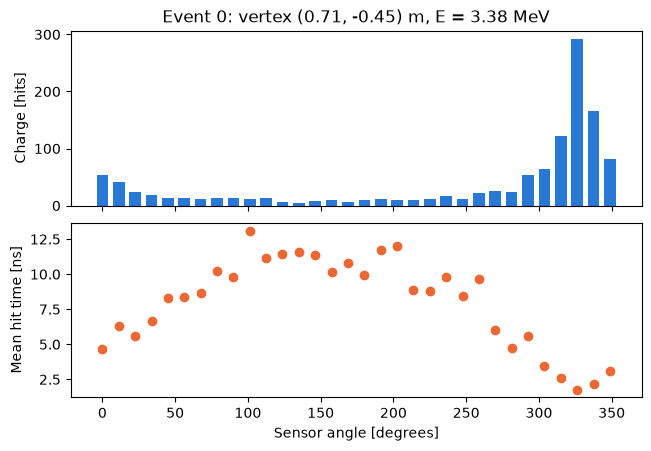

In [45]:
i = 0
phi = np.degrees(data.detector.sensor_phi)
charge, tau = data.response.charge[i], data.response.time_mean[i]
x0, y0, energy = data.truth.x[i], data.truth.y[i], data.truth.energy[i]

fig, (top, bottom) = plt.subplots(2, 1, figsize=(6.4, 4.4), sharex=True, constrained_layout=True)
top.bar(phi, charge, width=8, color="#2a78d6")
top.set_ylabel("Charge [hits]")
top.set_title(f"Event {data.truth.event_id[i]}: vertex ({x0:.2f}, {y0:.2f}) m, E = {energy:.2f} MeV")
bottom.plot(phi, tau, "o", color="#eb6834")
bottom.set_ylabel("Mean hit time [ns]")
bottom.set_xlabel("Sensor angle [degrees]")
plt.show()

## The network input

The neural networks of the next stage see the log charges and the charge-weighted relative mean times of every event,
an array of shape `[N, 2M]` (definition in [docs/physics.md](../docs/physics.md#network-input)).

In [41]:
x = network_input(data.response.charge, data.response.time_mean)
m = data.n_sensors
print("shape:", x.shape)
print("log charges, event 0, sensors 0-5:   ", np.round(x[0, :6], 2))
print("relative times, event 0, sensors 0-5:", np.round(x[0, m : m + 6], 2))

shape: (4000, 64)
log charges, event 0, sensors 0-5:    [4.01 3.76 3.18 2.94 2.71 2.71]
relative times, event 0, sensors 0-5: [0.21 1.85 1.15 2.24 3.86 3.98]


## Hits and photon paths

With `save_hits=True` every hit is stored with its sensor, its time and the history of its photon. With `save_tracks`
the photon paths are stored as polylines whose points carry a type: emission, scattering, reflection and the fate.

In [42]:
hits = pd.DataFrame(data.hits.arrays())
hits[hits.event_id == 0].head()

,event_id,sensor,time,n_scatter,n_reflect,path_length,is_noise
0,0,30,8.773934,2,0,1.626745,False
1,0,28,1.053467,0,0,0.235297,False
2,0,28,2.445054,1,0,0.262160,False
3,0,29,2.569298,0,0,0.167540,False
4,0,29,0.686170,1,0,0.224751,False


In [49]:
tracks = data.tracks
first = tracks.of_event(0)
print(first)
print(len(tracks), "tracks stored,", len(first), "of them from event 0")
_, _, kind = tracks.polyline(first[0])
#polyline() 是项目提供的方法，用于读取某条光子的传播路径。它会返回三个数组：x,y,kind
#这是 Python 的解包赋值。如果只想研究第三个返回值 kind，前两个坐标数组暂时不需要，就可以使用 _ 作为占位变量。
print("points of the first track:", [Interaction(k).name for k in kind])
fates, counts = np.unique(tracks.fate[first], return_counts=True)
#这是 NumPy 的统计函数。就是统计每种最终状态出现的次数。
print("fates of the tracks of event 0:", {Interaction(f).name: int(c) for f, c in zip(fates, counts, strict=True)})
#zip() 可以把两个序列中对应位置的元素配对。
#这里的 strict=True 表示要求两个序列长度相同，否则抛出错误。

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49]
100 tracks stored, 50 of them from event 0
points of the first track: ['EMIT', 'ABSORB_BULK']
fates of the tracks of event 0: {'DETECT': 17, 'ABSORB_BULK': 24, 'ABSORB_WALL': 9}


## Next steps

- The tasks for the next session are in [TASKS.md](../TASKS.md): T0 to T4, and the bonus T5.
- Larger data sets are easiest to make on the command line, e.g. `flashsim generate -n 50000 --seed 5 -o
  data/t2_full.h5`; on a cluster, see [examples/cluster](../examples/cluster/README.md).